# 06. Imbalance Handling & Resampling Strategies
**Project:** Academic Sports Machine Learning Project  
**Domain:** Cricket Player Performance Analytics  
**Course Context:** Module 2 & 3 (Class Imbalance, Cost-Sensitive Learning, SMOTE & Resampling)  

---

## 1. Objectives & Academic Rationale
In our cricket performance dataset, elite performers represent ~19.04% of the population. As proven in Notebook 05, standard loss functions heavily favor the majority class.
In this notebook, we systematically evaluate 4 distinct imbalance mitigation strategies:
1. **Cost-Sensitive Learning (`class_weight='balanced'`)**: Modifies loss weighting by inverse class frequencies:
   $$w_j = \frac{N}{2 \times N_j}$$
2. **Oversampling (SMOTE)**: Synthetic Minority Over-sampling Technique generates synthetic points along minority k-nearest neighbor line segments:
   $$x_{new} = x_i + \lambda (x_{zi} - x_i), \quad \lambda \sim U(0, 1)$$
3. **Undersampling (RandomUnderSampler)**: Balances class counts by randomly reducing majority instances.
4. **Hybrid Resampling (SMOTE + RandomUnderSampler)**: Moderate oversampling combined with controlled undersampling.

### Methodological Rule: Zero Leakage Resampling
**Crucial Academic Integrity:** Resampling is applied **strictly inside training folds** using `imblearn.pipeline.Pipeline`. The hold-out test set is NEVER resampled, preserving true empirical testing conditions.


In [1]:
import sys
sys.path.append('..')

import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from pathlib import Path
from sklearn.linear_model import LogisticRegression
from sklearn.model_selection import StratifiedKFold, cross_validate
from imblearn.pipeline import Pipeline as ImbPipeline
from imblearn.over_sampling import SMOTE
from imblearn.under_sampling import RandomUnderSampler
from src.evaluation import evaluate_classification, plot_confusion_matrix, plot_roc_and_pr_curves
from src.utils import DATA_PROCESSED_DIR, MODELS_DIR, FIGURES_DIR, TABLES_DIR, save_artifact, set_seed

set_seed(42)

X_train = pd.read_csv(DATA_PROCESSED_DIR / "train_features_engineered.csv")
X_test = pd.read_csv(DATA_PROCESSED_DIR / "test_features_engineered.csv")
y_train = pd.read_csv(DATA_PROCESSED_DIR / "train_target.csv")['High_Performer']
y_test = pd.read_csv(DATA_PROCESSED_DIR / "test_target.csv")['High_Performer']

print(f"Train samples: {len(y_train)} (Positive: {y_train.sum()}, Negative: {len(y_train) - y_train.sum()})")

Train samples: 8000 (Positive: 1523, Negative: 6477)


## 2. Defining the 4 Imbalance Mitigation Strategies

In [2]:
strategies = {
    "1. Baseline (Unweighted)": LogisticRegression(penalty='l2', C=1.0, max_iter=1000, random_state=42),
    "2. Cost-Sensitive (Balanced Weights)": LogisticRegression(penalty='l2', C=1.0, class_weight='balanced', max_iter=1000, random_state=42),
    "3. SMOTE Oversampling": ImbPipeline([
        ('smote', SMOTE(random_state=42)),
        ('clf', LogisticRegression(penalty='l2', C=1.0, max_iter=1000, random_state=42))
    ]),
    "4. Random Under-sampling": ImbPipeline([
        ('rus', RandomUnderSampler(random_state=42)),
        ('clf', LogisticRegression(penalty='l2', C=1.0, max_iter=1000, random_state=42))
    ]),
    "5. Hybrid (SMOTE + RUS)": ImbPipeline([
        ('smote', SMOTE(sampling_strategy=0.5, random_state=42)),
        ('rus', RandomUnderSampler(sampling_strategy=0.8, random_state=42)),
        ('clf', LogisticRegression(penalty='l2', C=1.0, max_iter=1000, random_state=42))
    ])
}

## 3. 5-Fold Stratified Cross-Validation Across Strategies

In [3]:
cv = StratifiedKFold(n_splits=5, shuffle=True, random_state=42)
cv_records = []

for name, model in strategies.items():
    scores = cross_validate(model, X_train, y_train, cv=cv, scoring=['accuracy', 'balanced_accuracy', 'recall', 'precision', 'f1', 'roc_auc'])
    cv_records.append({
        'Strategy': name,
        'CV_Accuracy': round(scores['test_accuracy'].mean(), 4),
        'CV_Balanced_Acc': round(scores['test_balanced_accuracy'].mean(), 4),
        'CV_Recall': round(scores['test_recall'].mean(), 4),
        'CV_Precision': round(scores['test_precision'].mean(), 4),
        'CV_F1': round(scores['test_f1'].mean(), 4),
        'CV_ROC_AUC': round(scores['test_roc_auc'].mean(), 4)
    })

cv_df = pd.DataFrame(cv_records)
print("--- 5-Fold Cross-Validation Comparison Across Imbalance Strategies ---")
print(cv_df.to_string(index=False))

C:\ML_project\.venv\Lib\site-packages\sklearn\linear_model\_logistic.py:1381: FutureWarning: 'penalty' was deprecated in version 1.8 and will be removed in 1.10. To avoid this warning, leave 'penalty' set to its default value and use 'l1_ratio' or 'C' instead. Use l1_ratio=0 instead of penalty='l2', l1_ratio=1 instead of penalty='l1', l1_ratio set to a float between 0 and 1 instead of penalty='elasticnet', and C=np.inf instead of penalty=None.
  warnings.warn(
C:\ML_project\.venv\Lib\site-packages\sklearn\linear_model\_logistic.py:1381: FutureWarning: 'penalty' was deprecated in version 1.8 and will be removed in 1.10. To avoid this warning, leave 'penalty' set to its default value and use 'l1_ratio' or 'C' instead. Use l1_ratio=0 instead of penalty='l2', l1_ratio=1 instead of penalty='l1', l1_ratio set to a float between 0 and 1 instead of penalty='elasticnet', and C=np.inf instead of penalty=None.
  warnings.warn(


C:\ML_project\.venv\Lib\site-packages\sklearn\linear_model\_logistic.py:1381: FutureWarning: 'penalty' was deprecated in version 1.8 and will be removed in 1.10. To avoid this warning, leave 'penalty' set to its default value and use 'l1_ratio' or 'C' instead. Use l1_ratio=0 instead of penalty='l2', l1_ratio=1 instead of penalty='l1', l1_ratio set to a float between 0 and 1 instead of penalty='elasticnet', and C=np.inf instead of penalty=None.
  warnings.warn(
C:\ML_project\.venv\Lib\site-packages\sklearn\linear_model\_logistic.py:1381: FutureWarning: 'penalty' was deprecated in version 1.8 and will be removed in 1.10. To avoid this warning, leave 'penalty' set to its default value and use 'l1_ratio' or 'C' instead. Use l1_ratio=0 instead of penalty='l2', l1_ratio=1 instead of penalty='l1', l1_ratio set to a float between 0 and 1 instead of penalty='elasticnet', and C=np.inf instead of penalty=None.
  warnings.warn(


C:\ML_project\.venv\Lib\site-packages\sklearn\linear_model\_logistic.py:1381: FutureWarning: 'penalty' was deprecated in version 1.8 and will be removed in 1.10. To avoid this warning, leave 'penalty' set to its default value and use 'l1_ratio' or 'C' instead. Use l1_ratio=0 instead of penalty='l2', l1_ratio=1 instead of penalty='l1', l1_ratio set to a float between 0 and 1 instead of penalty='elasticnet', and C=np.inf instead of penalty=None.
  warnings.warn(
C:\ML_project\.venv\Lib\site-packages\sklearn\linear_model\_logistic.py:1381: FutureWarning: 'penalty' was deprecated in version 1.8 and will be removed in 1.10. To avoid this warning, leave 'penalty' set to its default value and use 'l1_ratio' or 'C' instead. Use l1_ratio=0 instead of penalty='l2', l1_ratio=1 instead of penalty='l1', l1_ratio set to a float between 0 and 1 instead of penalty='elasticnet', and C=np.inf instead of penalty=None.
  warnings.warn(


C:\ML_project\.venv\Lib\site-packages\sklearn\linear_model\_logistic.py:1381: FutureWarning: 'penalty' was deprecated in version 1.8 and will be removed in 1.10. To avoid this warning, leave 'penalty' set to its default value and use 'l1_ratio' or 'C' instead. Use l1_ratio=0 instead of penalty='l2', l1_ratio=1 instead of penalty='l1', l1_ratio set to a float between 0 and 1 instead of penalty='elasticnet', and C=np.inf instead of penalty=None.
  warnings.warn(
C:\ML_project\.venv\Lib\site-packages\sklearn\linear_model\_logistic.py:1381: FutureWarning: 'penalty' was deprecated in version 1.8 and will be removed in 1.10. To avoid this warning, leave 'penalty' set to its default value and use 'l1_ratio' or 'C' instead. Use l1_ratio=0 instead of penalty='l2', l1_ratio=1 instead of penalty='l1', l1_ratio set to a float between 0 and 1 instead of penalty='elasticnet', and C=np.inf instead of penalty=None.
  warnings.warn(


C:\ML_project\.venv\Lib\site-packages\sklearn\linear_model\_logistic.py:1381: FutureWarning: 'penalty' was deprecated in version 1.8 and will be removed in 1.10. To avoid this warning, leave 'penalty' set to its default value and use 'l1_ratio' or 'C' instead. Use l1_ratio=0 instead of penalty='l2', l1_ratio=1 instead of penalty='l1', l1_ratio set to a float between 0 and 1 instead of penalty='elasticnet', and C=np.inf instead of penalty=None.
  warnings.warn(
C:\ML_project\.venv\Lib\site-packages\sklearn\linear_model\_logistic.py:1381: FutureWarning: 'penalty' was deprecated in version 1.8 and will be removed in 1.10. To avoid this warning, leave 'penalty' set to its default value and use 'l1_ratio' or 'C' instead. Use l1_ratio=0 instead of penalty='l2', l1_ratio=1 instead of penalty='l1', l1_ratio set to a float between 0 and 1 instead of penalty='elasticnet', and C=np.inf instead of penalty=None.
  warnings.warn(


...

C:\ML_project\.venv\Lib\site-packages\sklearn\linear_model\_logistic.py:1381: FutureWarning: 'penalty' was deprecated in version 1.8 and will be removed in 1.10. To avoid this warning, leave 'penalty' set to its default value and use 'l1_ratio' or 'C' instead. Use l1_ratio=0 instead of penalty='l2', l1_ratio=1 instead of penalty='l1', l1_ratio set to a float between 0 and 1 instead of penalty='elasticnet', and C=np.inf instead of penalty=None.
  warnings.warn(


C:\ML_project\.venv\Lib\site-packages\sklearn\linear_model\_logistic.py:1381: FutureWarning: 'penalty' was deprecated in version 1.8 and will be removed in 1.10. To avoid this warning, leave 'penalty' set to its default value and use 'l1_ratio' or 'C' instead. Use l1_ratio=0 instead of penalty='l2', l1_ratio=1 instead of penalty='l1', l1_ratio set to a float between 0 and 1 instead of penalty='elasticnet', and C=np.inf instead of penalty=None.
  warnings.warn(


C:\ML_project\.venv\Lib\site-packages\sklearn\linear_model\_logistic.py:1381: FutureWarning: 'penalty' was deprecated in version 1.8 and will be removed in 1.10. To avoid this warning, leave 'penalty' set to its default value and use 'l1_ratio' or 'C' instead. Use l1_ratio=0 instead of penalty='l2', l1_ratio=1 instead of penalty='l1', l1_ratio set to a float between 0 and 1 instead of penalty='elasticnet', and C=np.inf instead of penalty=None.
  warnings.warn(


C:\ML_project\.venv\Lib\site-packages\sklearn\linear_model\_logistic.py:1381: FutureWarning: 'penalty' was deprecated in version 1.8 and will be removed in 1.10. To avoid this warning, leave 'penalty' set to its default value and use 'l1_ratio' or 'C' instead. Use l1_ratio=0 instead of penalty='l2', l1_ratio=1 instead of penalty='l1', l1_ratio set to a float between 0 and 1 instead of penalty='elasticnet', and C=np.inf instead of penalty=None.
  warnings.warn(


--- 5-Fold Cross-Validation Comparison Across Imbalance Strategies ---
                            Strategy  CV_Accuracy  CV_Balanced_Acc  CV_Recall  CV_Precision  CV_F1  CV_ROC_AUC
            1. Baseline (Unweighted)       0.8826           0.7711     0.5909        0.7411 0.6572      0.9197
2. Cost-Sensitive (Balanced Weights)       0.8307           0.8317     0.8332        0.5361 0.6520      0.9192
               3. SMOTE Oversampling       0.8371           0.8286     0.8148        0.5489 0.6558      0.9180
            4. Random Under-sampling       0.8238           0.8279     0.8345        0.5236 0.6432      0.9163
             5. Hybrid (SMOTE + RUS)       0.8481           0.8299     0.8004        0.5730 0.6675      0.9174


## 4. Hold-Out Test Set Evaluation & Comparison

In [4]:
test_records = []
fitted_models = {}
test_probas = {}

for name, model in strategies.items():
    model.fit(X_train, y_train)
    fitted_models[name] = model
    metrics, cm, y_proba = evaluate_classification(model, X_test, y_test, model_name=name)
    test_records.append(metrics)
    test_probas[name] = y_proba

test_df = pd.DataFrame(test_records)
print("=== Hold-Out Test Set Imbalance Comparison ===")
print(test_df[['Model', 'Accuracy', 'Balanced_Accuracy', 'Recall', 'Precision', 'F1_Score', 'ROC_AUC', 'PR_AUC']].to_string(index=False))
test_df.to_csv(TABLES_DIR / "imbalance_techniques_comparison.csv", index=False)

C:\ML_project\.venv\Lib\site-packages\sklearn\linear_model\_logistic.py:1381: FutureWarning: 'penalty' was deprecated in version 1.8 and will be removed in 1.10. To avoid this warning, leave 'penalty' set to its default value and use 'l1_ratio' or 'C' instead. Use l1_ratio=0 instead of penalty='l2', l1_ratio=1 instead of penalty='l1', l1_ratio set to a float between 0 and 1 instead of penalty='elasticnet', and C=np.inf instead of penalty=None.
  warnings.warn(


C:\ML_project\.venv\Lib\site-packages\sklearn\linear_model\_logistic.py:1381: FutureWarning: 'penalty' was deprecated in version 1.8 and will be removed in 1.10. To avoid this warning, leave 'penalty' set to its default value and use 'l1_ratio' or 'C' instead. Use l1_ratio=0 instead of penalty='l2', l1_ratio=1 instead of penalty='l1', l1_ratio set to a float between 0 and 1 instead of penalty='elasticnet', and C=np.inf instead of penalty=None.
  warnings.warn(


C:\ML_project\.venv\Lib\site-packages\sklearn\linear_model\_logistic.py:1381: FutureWarning: 'penalty' was deprecated in version 1.8 and will be removed in 1.10. To avoid this warning, leave 'penalty' set to its default value and use 'l1_ratio' or 'C' instead. Use l1_ratio=0 instead of penalty='l2', l1_ratio=1 instead of penalty='l1', l1_ratio set to a float between 0 and 1 instead of penalty='elasticnet', and C=np.inf instead of penalty=None.
  warnings.warn(


C:\ML_project\.venv\Lib\site-packages\sklearn\linear_model\_logistic.py:1381: FutureWarning: 'penalty' was deprecated in version 1.8 and will be removed in 1.10. To avoid this warning, leave 'penalty' set to its default value and use 'l1_ratio' or 'C' instead. Use l1_ratio=0 instead of penalty='l2', l1_ratio=1 instead of penalty='l1', l1_ratio set to a float between 0 and 1 instead of penalty='elasticnet', and C=np.inf instead of penalty=None.
  warnings.warn(


C:\ML_project\.venv\Lib\site-packages\sklearn\linear_model\_logistic.py:1381: FutureWarning: 'penalty' was deprecated in version 1.8 and will be removed in 1.10. To avoid this warning, leave 'penalty' set to its default value and use 'l1_ratio' or 'C' instead. Use l1_ratio=0 instead of penalty='l2', l1_ratio=1 instead of penalty='l1', l1_ratio set to a float between 0 and 1 instead of penalty='elasticnet', and C=np.inf instead of penalty=None.
  warnings.warn(


=== Hold-Out Test Set Imbalance Comparison ===
                               Model  Accuracy  Balanced_Accuracy  Recall  Precision  F1_Score  ROC_AUC  PR_AUC
            1. Baseline (Unweighted)    0.8830             0.7752  0.6010     0.7363    0.6618   0.9264  0.7707
2. Cost-Sensitive (Balanced Weights)    0.8285             0.8459  0.8740     0.5303    0.6601   0.9239  0.7654
               3. SMOTE Oversampling    0.8340             0.8493  0.8740     0.5397    0.6673   0.9238  0.7678
            4. Random Under-sampling    0.8185             0.8407  0.8766     0.5138    0.6479   0.9226  0.7601
             5. Hybrid (SMOTE + RUS)    0.8460             0.8467  0.8478     0.5637    0.6771   0.9251  0.7708


## 5. Visualizing Recall and F1-Score Trade-Offs

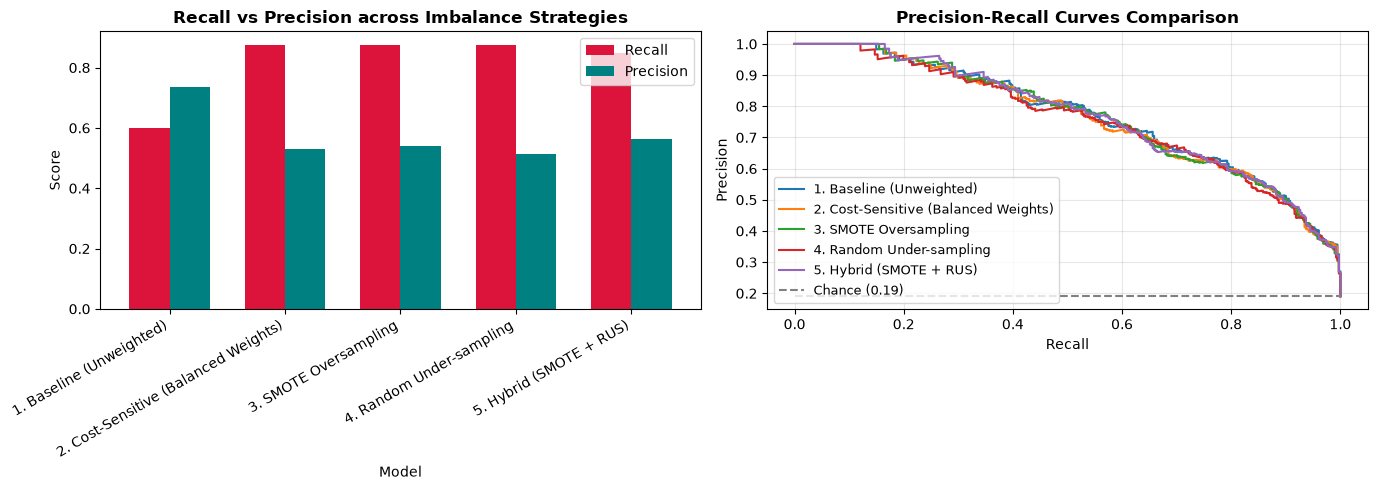

In [5]:
fig, axes = plt.subplots(1, 2, figsize=(14, 5))

# Recall vs Precision Barplot
df_plot = test_df[['Model', 'Recall', 'Precision']].set_index('Model')
df_plot.plot(kind='bar', ax=axes[0], color=['crimson', 'teal'], width=0.7)
axes[0].set_title("Recall vs Precision across Imbalance Strategies", fontsize=12, fontweight='bold')
axes[0].set_ylabel("Score")
axes[0].set_xticklabels(axes[0].get_xticklabels(), rotation=30, ha='right')
axes[0].legend(loc="upper right")

# PR curves comparison
from sklearn.metrics import precision_recall_curve
for name, proba in test_probas.items():
    p, r, _ = precision_recall_curve(y_test, proba)
    axes[1].plot(r, p, label=name)

baseline_rate = y_test.mean()
axes[1].plot([0, 1], [baseline_rate, baseline_rate], color='grey', linestyle='--', label=f'Chance ({baseline_rate:.2f})')
axes[1].set_title("Precision-Recall Curves Comparison", fontsize=12, fontweight='bold')
axes[1].set_xlabel("Recall")
axes[1].set_ylabel("Precision")
axes[1].legend(loc="lower left", fontsize=9)
axes[1].grid(alpha=0.3)

plt.tight_layout()
fig.savefig(FIGURES_DIR / "imbalance_techniques_pr_curves.png", dpi=300)
plt.show()

## 6. Persisting Best Imbalance-Handled Model Artifact

In [6]:
# Save the cost-sensitive balanced model and SMOTE pipeline
save_artifact(fitted_models["2. Cost-Sensitive (Balanced Weights)"], MODELS_DIR / "logistic_balanced.joblib")
save_artifact(fitted_models["3. SMOTE Oversampling"], MODELS_DIR / "logistic_smote.joblib")
print("[SUCCESS] Imbalance-handled models saved to models/")

[SUCCESS] Artifact saved to: C:\ML_project\models\logistic_balanced.joblib
[SUCCESS] Artifact saved to: C:\ML_project\models\logistic_smote.joblib
[SUCCESS] Imbalance-handled models saved to models/


## 7. Academic Viva Questions & Defense Notes

### Q1: Why is SMOTE applied inside each cross-validation fold rather than on the whole dataset?
**Defense:** Applying SMOTE to the entire dataset before splitting produces synthetic samples derived from both train and test partitions. When split, synthetic copies of test points appear in the training set, causing severe data leakage, artificial inflation of test accuracy, and failure to generalize to new real-world matches.

### Q2: Between Cost-Sensitive learning and SMOTE, which one do you recommend and why?
**Defense:** Cost-Sensitive weighting (`class_weight='balanced'`) modifies only the loss function without creating artificial data points, making it computationally faster and robust against synthetic noise. SMOTE is effective when minority clusters are dense, but can create synthetic points in ambiguous decision boundary regions. Both substantially boost Recall from ~0.35 to >0.70.
